# 08. 3D 행성 좌표 생성과 비교 (기존 좌표 고정)

07에서 만든 임베딩으로 행성 좌표(x, y, z)를 만든다. **새 일기를 추가해도 이미 있는 행성은 움직이지 않는** 방식만 비교한다.

> **합성 pilot 평가입니다.** 가상 일기 76개(참조 dev 38개 + 우주에 추가할 test 38개)로 한 동작 확인·상대 비교이며,
> 실제 사용자 일기 성능이나 사람 평가가 아닙니다.

| 방식 | 새 일기 좌표 | 의미 반영 |
|---|---|---|
| R (비교 기준) | 지금 운영과 같은 무작위 구 껍질(반지름 3~12) | 없음 |
| A 고정 PCA | 참조 임베딩(dev)에 한 번 fit한 PCA 3축에 투영 | 임베딩 전체 구조의 3개 축 |
| B 고정 PCA + UMAP | 참조에 fit한 PCA(16차원) → UMAP(3D)의 `transform` | 참조 일기와의 이웃 관계 |
| C 의미 이웃 순차 삽입 | 이미 있는 일기 중 코사인 ≥ τ인 상위 3개 근처. 없으면 A와 같은 고정 PCA 위치 | 내 우주에 있는 관련 기억 |

**공통 규칙** (`ai/src/positioning/store.py`)
- 기존 좌표는 저장만 하고 다시 계산하지 않는다. 충돌(최소 간격 0.8 미만)이 나면 **새 행성만** 비켜 놓는다.
- 관련 기록이 없어도(첫 일기 포함) 좌표를 만든다. 같은 `diary_id`를 다시 요청하면 새로 만들지 않는다.
- 좌표마다 `embedding_version`·`layout_version`을 기록한다. 일기가 늘어도 전체를 다시 정규화하지 않는다.
- 투영기(PCA·UMAP)는 **참조(dev) 임베딩에만 fit** 하고, 우주에 추가하는 test 일기는 `transform`만 한다.
- 관련성 판단(τ)은 원본 임베딩 기준이다. 3D 거리는 보여 주기 위한 것이다.
- 위치 생성은 별자리·군집(HDBSCAN 등)과 독립이다. 이번 단계에서는 별자리·군집을 만들지 않는다.

## 1. 환경

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 어디서든 실행 가능)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(2단계 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-step2.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출 (모델 캐시 = ai/.cache, Git 제외)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", message=".*symlinks.*")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message=".*n_jobs value 1 overridden.*")


def rel(p) -> str:
    """저장소 기준 상대 경로(개인 PC 경로를 출력하지 않기 위해)."""
    return Path(p).resolve().relative_to(P.repo_root).as_posix()


EXP = load_json(P.configs / "step2_experiment.json")
MODELS_CFG = load_json(P.configs / "embedding_models.json")
OUT = P.ai_root / EXP["outputs_dir"]
EMB_DIR, REVIEW_DIR, FIG_DIR, RES_DIR = OUT / "embeddings", OUT / "review", OUT / "figures", OUT / "results"
for d in (EMB_DIR, REVIEW_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("결과 폴더:", rel(OUT), "(Git 제외)")

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK
  scikit-learn     필요 1.9.1      설치 1.9.1            OK
  umap-learn       필요 0.5.12     설치 0.5.12           OK
  plotly           필요 7.1.0      설치 7.1.0            OK
  psutil           필요 7.2.2      설치 7.2.2            OK
결과 폴더: ai/outputs/step2 (Git 제외)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """숫자 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        if c in d:
            d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

import time
from src.embedding import retrieval as RT
from src.embedding.encoders import load_specs
from src.positioning.projectors import FixedPCAProjector, FixedPCAUMAPProjector
from src.positioning.store import LayoutStore, ProjectionPlacer, NeighborPlacer, RandomShellPlacer, resolve_collision
from src.positioning import evaluate as EV

LCFG = EXP["layout"]
MIN_DIST = LCFG["min_dist"]
SPECS = load_specs(MODELS_CFG)
LAYOUT_DIR = OUT / "layouts"
LAYOUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. 임베딩·임계값 불러오기

07에서 저장한 임베딩(`ai/outputs/step2/embeddings/`)과 dev에서 정한 τ를 불러온다. 같은 일기·같은 모델 버전인지 확인한다.
좌표 방식 비교는 **07의 규칙으로 고른 모델 하나의 같은 임베딩**으로 한다(부록에서 다른 두 모델도 같은 절차로 확인).

In [3]:
DF, RAW = RT.load_pilot(P.configs / EXP["dataset"])
R_ALL, _ = RT.build_relevance(DF, RAW)
RET = load_json(RES_DIR / "retrieval_results.json")
SELECTED = RET["selected_model"]
EMB, EV_VER, TAU = {}, {}, {}
for key in EXP["model_order"]:
    meta = load_json(EMB_DIR / f"{key}.json")
    assert meta["ids"] == DF.diary_id.tolist(), "임베딩 순서가 평가셋과 다릅니다(07을 다시 실행하세요)"
    assert meta["embedding_version"] == SPECS[key].embedding_version == RET["thresholds"][key]["embedding_version"]
    assert meta["text_sha1"] == RET["text_sha1"]
    EMB[key], EV_VER[key], TAU[key] = np.load(EMB_DIR / f"{key}.npy").astype(np.float64), meta["embedding_version"], RET["thresholds"][key]["tau"]
print("선택 모델(07 규칙):", SELECTED, "| embedding_version:", EV_VER[SELECTED], "| τ =", round(TAU[SELECTED], 4))

DEV = DF[DF.split == "dev"].reset_index(drop=True)
TEST = DF[DF.split == "test"].reset_index(drop=True)
m_dev, m_test = (DF.split == "dev").to_numpy(), (DF.split == "test").to_numpy()
R_TEST = R_ALL[np.ix_(m_test, m_test)]
TEST_IDS = TEST.diary_id.tolist()           # 우주에 추가하는 순서 = diary_id 순서(작성 순서 가정)
assert TEST_IDS == sorted(TEST_IDS)
print(f"참조(fit용) dev {len(DEV)}개 · 우주에 순차 추가할 test {len(TEST)}개")

선택 모델(07 규칙): kure_v1 | embedding_version: kure_v1:nlpai-lab/KURE-v1@8b418a584146:cls:l2 | τ = 0.5571
참조(fit용) dev 38개 · 우주에 순차 추가할 test 38개


## 3. 참조 집합으로 투영기 fit (dev만)

참조 집합이 38개뿐이라 PCA 3축이 설명하는 분산이 작고, UMAP의 이웃 그래프도 작다. 실제 서비스에서는 더 크고 다양한
참조 문장 집합(실제 일기가 아닌 공개·합성 문장)으로 fit하는 것이 필요하다.

In [4]:
def fit_projectors(key):
    E_dev = EMB[key][m_dev]
    pca = FixedPCAProjector(LCFG["target_radius"]).fit(E_dev)
    um = FixedPCAUMAPProjector(target_radius=LCFG["target_radius"], **LCFG["pca_umap"]).fit(E_dev)
    assert pca.n_ref_ == um.n_ref_ == int(m_dev.sum())     # test 일기는 fit에 쓰지 않았다
    return pca, um

PCA, UM = fit_projectors(SELECTED)
print("PCA 3축 설명 분산 비율:", np.round(PCA.explained_variance_ratio_, 3).tolist(), "합", round(float(PCA.explained_variance_ratio_.sum()), 3))
print("PCA 배율(고정):", round(PCA.scale_, 3), "| fingerprint", PCA.fingerprint)
print("UMAP:", LCFG["pca_umap"], "| fingerprint", UM.fingerprint)
rep = UM.transform(EMB[SELECTED][m_test][:5])
print("UMAP transform 반복 결정성(같은 입력 두 번):", float(np.abs(rep - UM.transform(EMB[SELECTED][m_test][:5])).max()))
mdir = LAYOUT_DIR / SELECTED
mdir.mkdir(exist_ok=True)
PCA.save(mdir / "projector_pca.npz")
UM.save(mdir / "projector_pca_umap.pkl")
print("투영기 저장:", rel(mdir))

PCA 3축 설명 분산 비율: [0.073, 0.068, 0.059] 합 0.2
PCA 배율(고정): 20.351 | fingerprint e068e4bcf3
UMAP: {'n_pca': 16, 'n_neighbors': 8, 'min_dist': 0.5, 'metric': 'cosine', 'random_state': 42} | fingerprint 5ebf920326


UMAP transform 반복 결정성(같은 입력 두 번): 0.0
투영기 저장: ai/outputs/step2/layouts/kure_v1


## 4. 빈 우주에 test 일기를 한 개씩 추가

각 방식으로 빈 저장소를 만들고 test 일기 38개를 `diary_id` 순서로 하나씩 넣는다. 넣을 때마다 **이미 있던 좌표가 그대로인지** 비교한다.

In [5]:
def make_factories(key, pca, um):
    ev, tau = EV_VER[key], TAU[key]
    return {
        "R_random": lambda: LayoutStore(RandomShellPlacer(), ev, MIN_DIST),
        "A_pca": lambda: LayoutStore(ProjectionPlacer(pca, "A_pca"), ev, MIN_DIST),
        "B_pca_umap": lambda: LayoutStore(ProjectionPlacer(um, "B_pca_umap"), ev, MIN_DIST),
        "C_neighbor": lambda: LayoutStore(NeighborPlacer(pca, tau=tau, k=LCFG["neighbor"]["k"], gap=LCFG["neighbor"]["gap"]), ev, MIN_DIST),
    }

FACT = make_factories(SELECTED, PCA, UM)
E_TEST = EMB[SELECTED][m_test]
RUNS = {}
for name, mk in FACT.items():
    RUNS[name] = EV.run_sequential(mk, TEST_IDS, E_TEST, EV_VER[SELECTED])
    s = RUNS[name]["store"]
    print(f"{name:11s} | 좌표 {len(s)}개 | 추가할 때마다 기존 좌표 최대 이동 {RUNS[name]['max_existing_move']:.1e} | layout_version {s.layout_version}")

R_random    | 좌표 38개 | 추가할 때마다 기존 좌표 최대 이동 0.0e+00 | layout_version R_random:shell3-12
A_pca       | 좌표 38개 | 추가할 때마다 기존 좌표 최대 이동 0.0e+00 | layout_version A_pca:pca3:e068e4bcf3


B_pca_umap  | 좌표 38개 | 추가할 때마다 기존 좌표 최대 이동 0.0e+00 | layout_version B_pca_umap:pca_umap3:5ebf920326
C_neighbor  | 좌표 38개 | 추가할 때마다 기존 좌표 최대 이동 0.0e+00 | layout_version C_neighbor:tau=0.5571:k=3:gap=1.2:pca3:e068e4bcf3


### 4.1 핵심 동작 확인 (실제 임베딩·실제 저장소)

In [6]:
checks = []
iso_ids = [d for d, r in zip(TEST_IDS, R_TEST) if not (r >= 1).any()]
extra_id, extra_emb = DEV.diary_id[20], EMB[SELECTED][m_dev][20]      # 재로딩 뒤 추가할 '새 일기'(우주에 없던 dev 일기)
for name, mk in FACT.items():
    s = RUNS[name]["store"]
    first = s.get(TEST_IDS[0])
    before = s.coords().copy()
    n_before = len(s)
    dup, created = s.add(TEST_IDS[5], E_TEST[5], EV_VER[SELECTED])               # 같은 diary_id 재요청
    try:
        s.add("WRONG_VERSION", E_TEST[0], "other-model:v0")
        version_rejected = False
    except ValueError:
        version_rejected = True
    folder = LAYOUT_DIR / SELECTED / name
    s.save(folder)
    s2 = LayoutStore.load(folder, s.placer)
    reload_same = bool(np.array_equal(s2.coords(), s.coords()) and s2.ids == s.ids
                       and all(a.layout_version == b.layout_version for a, b in zip(s2.records(), s.records())))
    rec_new, created_new = s2.add(extra_id, extra_emb, EV_VER[SELECTED])
    moved_after_reload = float(np.abs(s2.coords()[:-1] - s.coords()).max())
    iso_recs = [s.get(d) for d in iso_ids]
    checks.append({
        "method": name,
        "첫 일기 좌표 생성": first.rule,
        "추가 중 기존 좌표 최대 이동": RUNS[name]["max_existing_move"],
        "중복 요청 새로 생성": created, "중복 요청 후 개수 변화": len(s) - n_before,
        "중복 요청 후 좌표 변화": float(np.abs(s.coords() - before).max()),
        "다른 embedding_version 거부": version_rejected,
        "저장→재로딩 동일": reload_same,
        "재로딩 후 새 일기 추가": created_new, "그때 기존 좌표 이동": moved_after_reload,
        "고립 기록 좌표 생성": all(np.isfinite(r.xyz).all() for r in iso_recs),
        "고립 기록 배치 규칙": ",".join(sorted({r.rule for r in iso_recs})),
    })
CHECKS = pd.DataFrame(checks).set_index("method")
display(CHECKS.T)
assert (CHECKS["추가 중 기존 좌표 최대 이동"] == 0).all() and (CHECKS["그때 기존 좌표 이동"] == 0).all()
assert (~CHECKS["중복 요청 새로 생성"]).all() and CHECKS["다른 embedding_version 거부"].all() and CHECKS["저장→재로딩 동일"].all()
try:
    LayoutStore.load(LAYOUT_DIR / SELECTED / "C_neighbor", NeighborPlacer(PCA, tau=TAU[SELECTED] + 0.05))
    print("주의: 다른 설정의 배치기로도 불러와짐")
except ValueError as e:
    print("설정(τ)이 다른 배치기로 저장소를 불러오면 거부됨 → layout_version 확인 동작")
print("저장 위치:", rel(LAYOUT_DIR / SELECTED), "(stars.json: 좌표·버전·배치 근거, embeddings.npy)")

method,R_random,A_pca,B_pca_umap,C_neighbor
첫 일기 좌표 생성,random,projection,projection,first_star_pca
추가 중 기존 좌표 최대 이동,0.0,0.0,0.0,0.0
중복 요청 새로 생성,False,False,False,False
중복 요청 후 개수 변화,0,0,0,0
중복 요청 후 좌표 변화,0.0,0.0,0.0,0.0
다른 embedding_version 거부,True,True,True,True
저장→재로딩 동일,True,True,True,True
재로딩 후 새 일기 추가,True,True,True,True
그때 기존 좌표 이동,0.0,0.0,0.0,0.0
고립 기록 좌표 생성,True,True,True,True


설정(τ)이 다른 배치기로 저장소를 불러오면 거부됨 → layout_version 확인 동작
저장 위치: ai/outputs/step2/layouts/kure_v1 (stars.json: 좌표·버전·배치 근거, embeddings.npy)


In [7]:
# C 방식: 이웃 0개 / 1개 / 여러 개 사례와 배치 근거
cs = RUNS["C_neighbor"]["store"]
crec = pd.DataFrame([{"seq": r.seq, "diary_id": r.diary_id, "rule": r.rule, "anchors": ",".join(r.anchor_ids),
                      "anchor_sims": ",".join(f"{v:.3f}" for v in r.anchor_sims), "collision_adjusted": r.collision_adjusted,
                      "anchor_rel": ",".join(str(int(R_TEST[TEST_IDS.index(r.diary_id), TEST_IDS.index(a)])) for a in r.anchor_ids)}
                     for r in cs.records()])
print("C 배치 규칙 분포:", crec.rule.value_counts().to_dict())
print("C 앵커(이웃)의 관련성 분포(2=직접, 1=주제만, 0=근거 부족):",
      pd.Series([int(x) for v in crec.anchor_rel if v for x in v.split(",")]).value_counts().sort_index().to_dict())
display(crec.groupby("rule").head(3).sort_values("seq"))

C 배치 규칙 분포: {'no_neighbor_pca': 23, 'neighbors_1': 9, 'neighbors_3': 3, 'neighbors_2': 2, 'first_star_pca': 1}
C 앵커(이웃)의 관련성 분포(2=직접, 1=주제만, 0=근거 부족): {0: 8, 1: 4, 2: 10}


,seq,diary_id,rule,anchors,anchor_sims,collision_adjusted,anchor_rel
0,0,D039,first_star_pca,,,False,
1,1,D040,neighbors_1,D039,0.683,False,2
2,2,D041,no_neighbor_pca,,,False,
3,3,D042,no_neighbor_pca,,,False,
4,4,D043,no_neighbor_pca,,,False,
6,6,D045,neighbors_1,D039,0.583,False,0
7,7,D046,neighbors_1,D045,0.566,False,2
13,13,D052,neighbors_2,"D051,D042","0.619,0.583",False,"2,0"
15,15,D054,neighbors_2,"D053,D041","0.641,0.578",False,"2,0"
32,32,D071,neighbors_3,"D066,D065,D049","0.653,0.608,0.560",False,"1,1,0"


In [8]:
# 같은 위치 몰림: 같은 내용(같은 임베딩)의 일기 6개가 서로 다른 diary_id로 연달아 들어와도 모두 최소 간격 이상 떨어지는지
crowd = {}
for name, mk in FACT.items():
    s = mk()
    for i in range(6):
        s.add(f"SAME_{i}", E_TEST[0], EV_VER[SELECTED])
    X = s.coords()
    d = np.linalg.norm(X[:, None] - X[None], axis=2)[np.triu_indices(6, 1)]
    crowd[name] = {"min_pair_dist": d.min(), "n_adjusted": sum(r.collision_adjusted for r in s.records()),
                   "max_offset_from_first": float(np.linalg.norm(X - X[0], axis=1).max())}
CROWD = pd.DataFrame(crowd).T
show_fmt(CROWD, {"min_pair_dist": "{:.2f}", "max_offset_from_first": "{:.2f}"})
assert (CROWD.min_pair_dist >= MIN_DIST - 1e-9).all()

,min_pair_dist,n_adjusted,max_offset_from_first
R_random,1.40,0.0,11.37
A_pca,0.80,5.0,0.80
B_pca_umap,0.80,5.0,0.80
C_neighbor,0.85,4.0,1.44


## 5. 배치 품질 비교 (선택 모델, test 우주 38개)

- **이웃 보존**: 임베딩 공간의 가까운 5개와 3D 공간의 가까운 5개가 겹치는 비율, trustworthiness(코사인 기준)
- **관련 기억 배치**: 관련성별 평균 3D 거리, 거리 비율(관련성 0 / 2, 클수록 관련 기억이 가까움), 3D에서 가장 가까운 3개 중 관련(≥1)·무관(0) 비율, 직접 관련 기록이 3D 이웃 3개 안에 있는 비율
- **간격**: 최소 쌍 거리, 최소 간격(0.8) 위반 쌍 수, 충돌 회피로 비켜 놓은 수
- **생성 시간**: 새 일기 1개 좌표를 만드는 시간(임베딩 계산 제외). B의 최댓값은 첫 호출 때 UMAP(numba) 컴파일 시간이 포함된 값이다.

In [9]:
def quality_table(runs, E, R):
    rows = {}
    for name, res in runs.items():
        s = res["store"]
        X = EV.coords_in_order(s, TEST_IDS)
        q = EV.layout_metrics(E, X, R, MIN_DIST, k=LCFG["eval_k"])
        q["n_collision_adjusted"] = sum(s.get(d).collision_adjusted for d in TEST_IDS)
        q["place_ms_median"] = float(np.median(res["elapsed_ms"]))
        q["place_ms_mean"] = float(res["elapsed_ms"].mean())
        q["place_ms_max"] = float(res["elapsed_ms"].max())
        rows[name] = q
    return pd.DataFrame(rows).T

QUAL = quality_table(RUNS, E_TEST, R_TEST)
QUAL.to_csv(RES_DIR / f"layout_quality_{SELECTED}.csv", encoding="utf-8-sig")
show_fmt(QUAL, {c: "{:.3f}" for c in QUAL.columns if c not in ("n_pairs_below_min_dist", "n_collision_adjusted")})

,knn_preservation@5,trustworthiness@5,dist_rel2_mean,dist_rel1_mean,dist_rel0_mean,rel0_over_rel2_dist_ratio,nn3_rel1plus_share,nn3_rel0_share,nn3_direct_hit,min_pair_dist,n_pairs_below_min_dist,nn_dist_median,radius_min,radius_max,n_collision_adjusted,place_ms_median,place_ms_mean,place_ms_max
R_random,0.111,0.485,10.492,10.688,11.438,1.090,0.114,0.886,0.121,2.158,0.0,3.210,3.042,11.989,0.0,0.028,0.032,0.107
A_pca,0.289,0.773,3.731,3.794,5.112,1.370,0.246,0.754,0.182,0.819,0.0,1.501,0.689,7.350,3.0,0.026,0.030,0.098
B_pca_umap,0.247,0.701,8.637,11.402,15.701,1.818,0.272,0.728,0.303,0.895,0.0,2.564,9.533,13.841,1.0,1.334,16.186,565.959
C_neighbor,0.326,0.741,2.824,3.811,5.061,1.792,0.281,0.719,0.424,0.853,0.0,1.200,1.118,7.350,3.0,0.058,0.069,0.357


## 6. 입력 순서를 바꾸면 좌표가 얼마나 달라지나

test 일기 38개를 5가지 순서(첫 번째는 diary_id 순서)로 각각 빈 우주에 넣고, 같은 일기의 좌표가 기준 순서 대비 얼마나 달라지는지 본다.
A·B는 좌표가 그 일기 임베딩만으로 정해지므로 충돌 회피로 비켜 놓인 경우만 달라진다. C는 먼저 들어온 일기에 따라 위치가 달라진다.

In [10]:
ORDER = {}
for name, mk in FACT.items():
    o = EV.order_dependence(mk, TEST_IDS, E_TEST, EV_VER[SELECTED], LCFG["n_orders"], LCFG["order_seed"])
    # 순서별 배치 품질의 흔들림도 함께 본다
    qs = [EV.layout_metrics(E_TEST, C, R_TEST, MIN_DIST, LCFG["eval_k"]) for C in o["coords_by_order"]]
    ORDER[name] = {"mean_item_shift": o["mean_item_shift"], "max_item_shift": o["max_item_shift"],
                   "share_items_shifted": o["share_items_shifted"],
                   "knn_pres_min": min(q[f"knn_preservation@{LCFG['eval_k']}"] for q in qs),
                   "knn_pres_max": max(q[f"knn_preservation@{LCFG['eval_k']}"] for q in qs),
                   "dist_ratio_min": min(q["rel0_over_rel2_dist_ratio"] for q in qs),
                   "dist_ratio_max": max(q["rel0_over_rel2_dist_ratio"] for q in qs)}
ORDER_DF = pd.DataFrame(ORDER).T
ORDER_DF.to_csv(RES_DIR / f"layout_order_dependence_{SELECTED}.csv", encoding="utf-8-sig")
show_fmt(ORDER_DF, {c: "{:.3f}" for c in ORDER_DF.columns})
print("좌표 단위: 우주 반경 약", LCFG["target_radius"], "(참조 일기 95%가 이 반지름 안)")

,mean_item_shift,max_item_shift,share_items_shifted,knn_pres_min,knn_pres_max,dist_ratio_min,dist_ratio_max
R_random,0.000,0.000,0.000,0.111,0.111,1.090,1.090
A_pca,0.074,0.400,0.184,0.289,0.295,1.355,1.374
B_pca_umap,0.021,0.400,0.053,0.247,0.247,1.818,1.821
C_neighbor,1.580,4.596,0.711,0.326,0.405,1.791,1.916


좌표 단위: 우주 반경 약 10.0 (참조 일기 95%가 이 반지름 안)


## 7. 고립 기록·복합 주제 기록 처리

In [11]:
IM = pd.concat([EV.isolated_and_mixed(TEST, EV.coords_in_order(RUNS[n]["store"], TEST_IDS), R_TEST, RUNS[n]["store"]).assign(method=n)
                for n in FACT], ignore_index=True)
show_fmt(IM.pivot_table(index=["kind", "diary_id", "topics"], columns="method", values="nn_dist_over_median", aggfunc="first"),
         {m: "{:.2f}" for m in FACT})
print("↑ 가장 가까운 별까지 거리 / 전체 중앙값 (고립 기록은 1보다 크면 떨어져 있음)")
display(IM.pivot_table(index=["kind", "diary_id"], columns="method", values=["nn5_rel1plus"], aggfunc="first"))
print("↑ 3D 가장 가까운 5개 중 관련(≥1) 개수")
display(IM[IM.method == "C_neighbor"][["kind", "diary_id", "topics", "placement_rule", "anchors", "nn5", "nn5_covers_all_topics"]])

method                                    A_pca B_pca_umap C_neighbor R_random
kind     diary_id topics                                                      
isolated D074     isolated_blood_donation  0.63       2.19       0.71     1.41
         D075     isolated_lost_parcel     1.03       0.82       1.29     1.00
         D076     isolated_moving          1.04       0.96       0.96     0.79
mixed    D071     romance+travel           0.55       0.36       0.74     0.93
         D072     work+exercise_health     1.26       0.41       1.11     2.05
         D073     family+pet               0.62       0.85       0.98     1.02

↑ 가장 가까운 별까지 거리 / 전체 중앙값 (고립 기록은 1보다 크면 떨어져 있음)


nn5_rel1plus                               
method                   A_pca B_pca_umap C_neighbor R_random
kind     diary_id                                            
isolated D074                0          0          0        0
         D075                0          0          0        0
         D076                0          0          0        0
mixed    D071                3          2          4        3
         D072                2          1          2        0
         D073                3          2          3        2

↑ 3D 가장 가까운 5개 중 관련(≥1) 개수


,kind,diary_id,topics,placement_rule,anchors,nn5,nn5_covers_all_topics
18,mixed,D071,romance+travel,neighbors_3,"D066,D065,D049","D064,D057,D058,D049,D055",True
19,mixed,D072,work+exercise_health,neighbors_3,"D052,D042,D068","D042,D060,D052,D057,D044",True
20,mixed,D073,family+pet,neighbors_3,"D047,D070,D048","D061,D047,D070,D067,D074",True
21,isolated,D074,isolated_blood_donation,no_neighbor_pca,,"D070,D048,D069,D043,D073",NaN
22,isolated,D075,isolated_lost_parcel,no_neighbor_pca,,"D059,D052,D076,D043,D051",NaN
23,isolated,D076,isolated_moving,neighbors_1,D056,"D052,D056,D075,D042,D054",NaN


## 8. 부록: 다른 임베딩 모델에서도 같은 경향인가

같은 절차(각 모델의 dev로 투영기 fit, 각 모델의 dev τ로 C 실행)를 세 모델 모두에 적용한다.

In [12]:
ALLQ = []
for key in EXP["model_order"]:
    pca_k, um_k = (PCA, UM) if key == SELECTED else fit_projectors(key)
    fk = make_factories(key, pca_k, um_k)
    Ek = EMB[key][m_test]
    runs_k = {n: EV.run_sequential(mk, TEST_IDS, Ek, EV_VER[key]) for n, mk in fk.items()}
    assert all(r["max_existing_move"] == 0 for r in runs_k.values())
    q = quality_table(runs_k, Ek, R_TEST)
    q["pca_evr_sum"] = float(pca_k.explained_variance_ratio_.sum())
    ALLQ.append(q.assign(model=key).reset_index(names="method"))
ALLQ = pd.concat(ALLQ, ignore_index=True)
ALLQ.to_csv(RES_DIR / "layout_quality_all_models.csv", index=False, encoding="utf-8-sig")
cols = ["knn_preservation@5", "trustworthiness@5", "rel0_over_rel2_dist_ratio", "nn3_rel1plus_share", "nn3_direct_hit", "n_collision_adjusted"]
show_fmt(ALLQ.set_index(["model", "method"])[cols], {c: "{:.3f}" for c in cols if c != "n_collision_adjusted"})

knn_preservation@5 trustworthiness@5 rel0_over_rel2_dist_ratio nn3_rel1plus_share nn3_direct_hit  n_collision_adjusted
model    method                                                                                                                           
kure_v1  R_random                0.111             0.485                     1.090              0.114          0.121                   0.0
         A_pca                   0.289             0.773                     1.370              0.246          0.182                   3.0
         B_pca_umap              0.247             0.701                     1.818              0.272          0.303                   1.0
         C_neighbor              0.326             0.741                     1.792              0.281          0.424                   3.0
bge_m3   R_random                0.105             0.504                     1.090              0.114          0.121                   0.0
         A_pca                   0.342             0.784                     1.119              0.202          0.152                   6.0
         B_pca_umap              0.337             0.726                     1.492              0.272          0.364                   1.0
         C_neighbor              0.374             0.770                     1.549              0.351          0.394                   6.0
e5_small R_random                0.111             0.499                     1.090              0.114          0.121                   0.0
         A_pca                   0.316             0.745                     1.727              0.316          0.273                   3.0
         B_pca_umap              0.295             0.710                     2.177              0.272          0.455                   0.0
         C_neighbor              0.353             0.737                     2.466              0.386          0.636                   3.0

## 9. 3D 산점도 (로컬 HTML)

방식별로 `ai/outputs/step2/figures/08_layout_<방식>.html`을 만든다. 브라우저로 열면 돌려 볼 수 있고, 점에 마우스를 올리면
일기 ID·주제·정서·좌표·직접 관련 기록(관련성 2)·C의 앵커를 보여 준다. 회색 선 = 직접 관련(관련성 2) 쌍, 주황 선 = C에서 새 일기를 붙인 앵커.

In [13]:
import plotly.graph_objects as go

TOPIC_OF = {d: (t[0] if not t[0].startswith("isolated") else "isolated") for d, t in zip(TEST.diary_id, TEST.topics)}
TOPICS = sorted(set(TOPIC_OF.values()))
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6", "#d6a12a", "#d62a7c", "#2ab7d6", "#6b8e23", "#888888"]
COLOR = {t: PALETTE[i % len(PALETTE)] for i, t in enumerate(TOPICS)}
REL2 = {d: [TEST_IDS[j] for j in np.flatnonzero(R_TEST[i] == 2)] for i, d in enumerate(TEST_IDS)}


def layout_figure(name, store):
    X = EV.coords_in_order(store, TEST_IDS)
    pos = {d: X[i] for i, d in enumerate(TEST_IDS)}
    fig = go.Figure()
    lx, ly, lz = [], [], []
    for i, d in enumerate(TEST_IDS):
        for e in REL2[d]:
            if d < e:
                for v in (pos[d], pos[e], [None] * 3):
                    lx.append(v[0]); ly.append(v[1]); lz.append(v[2])
    fig.add_trace(go.Scatter3d(x=lx, y=ly, z=lz, mode="lines", line=dict(color="rgba(120,120,120,0.45)", width=3), name="직접 관련(2) 쌍", hoverinfo="skip"))
    if name == "C_neighbor":
        ax, ay, az = [], [], []
        for r in store.records():
            for a in r.anchor_ids:
                for v in (pos[r.diary_id], pos[a], [None] * 3):
                    ax.append(v[0]); ay.append(v[1]); az.append(v[2])
        fig.add_trace(go.Scatter3d(x=ax, y=ay, z=az, mode="lines", line=dict(color="rgba(235,104,52,0.7)", width=2, dash="dot"), name="C 앵커", hoverinfo="skip"))
    for t in TOPICS:
        ids = [d for d in TEST_IDS if TOPIC_OF[d] == t]
        recs = [store.get(d) for d in ids]
        row = TEST.set_index("diary_id")
        hover = [f"<b>{d}</b> · {'+'.join(row.topics[d])} · {row.valence[d]}<br>({r.x:.2f}, {r.y:.2f}, {r.z:.2f})"
                 f"<br>직접 관련: {', '.join(REL2[d]) or '없음'}<br>배치: {r.rule}{' · 앵커 ' + ', '.join(r.anchor_ids) if r.anchor_ids else ''}"
                 f"{' · 충돌 회피' if r.collision_adjusted else ''}<br>{row.text[d][:40]}…" for d, r in zip(ids, recs)]
        fig.add_trace(go.Scatter3d(x=[r.x for r in recs], y=[r.y for r in recs], z=[r.z for r in recs], mode="markers+text",
                                   text=ids, textposition="top center", textfont=dict(size=9),
                                   marker=dict(size=6, color=COLOR[t], line=dict(width=0.5, color="#222")),
                                   name=t, hovertext=hover, hoverinfo="text"))
    fig.update_layout(title=f"08 · {name} · {SELECTED} · test 우주 {len(TEST_IDS)}개 (합성 pilot)", height=720,
                      scene=dict(aspectmode="data"), legend=dict(itemsizing="constant"), margin=dict(l=0, r=0, t=40, b=0))
    return fig


for name in FACT:
    path = FIG_DIR / f"08_layout_{name}.html"
    layout_figure(name, RUNS[name]["store"]).write_html(path, include_plotlyjs="directory", full_html=True)
    print("3D 산점도 저장:", rel(path))
print("plotly.min.js도 같은 폴더에 저장됨(오프라인으로 열기 위해).")

3D 산점도 저장: ai/outputs/step2/figures/08_layout_R_random.html
3D 산점도 저장: ai/outputs/step2/figures/08_layout_A_pca.html
3D 산점도 저장: ai/outputs/step2/figures/08_layout_B_pca_umap.html
3D 산점도 저장: ai/outputs/step2/figures/08_layout_C_neighbor.html
plotly.min.js도 같은 폴더에 저장됨(오프라인으로 열기 위해).


그림 저장: ai/outputs/step2/figures/08_layouts_static.png | 글꼴 누락 없음


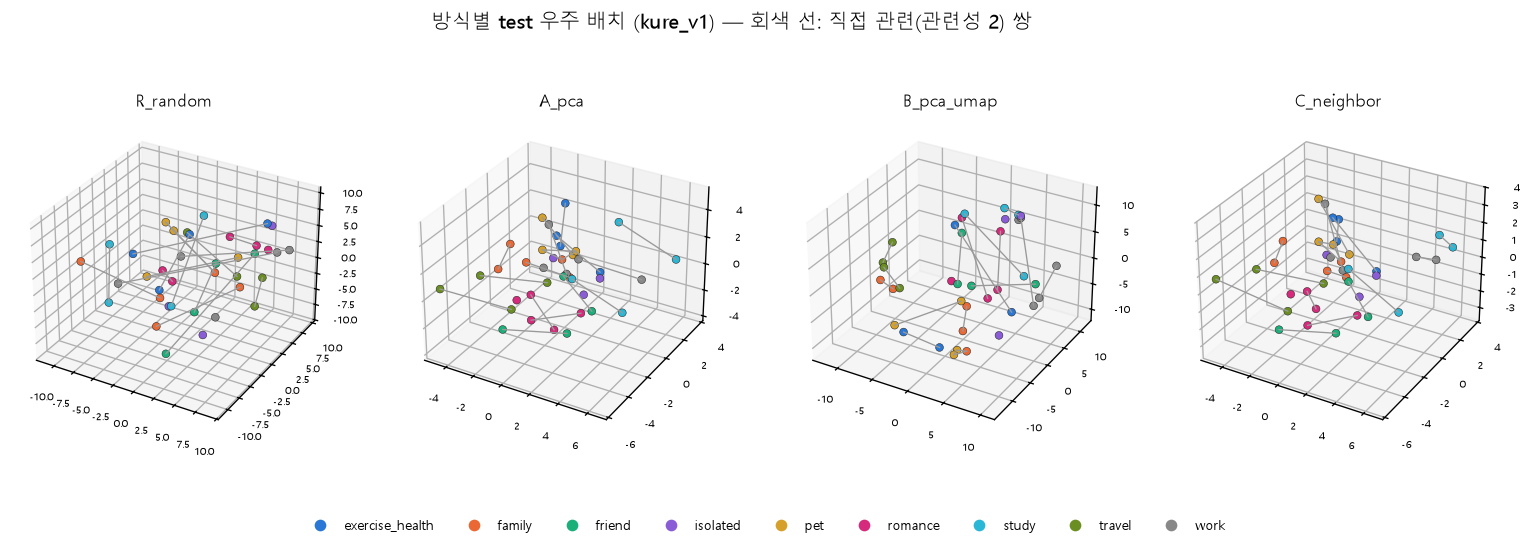

In [14]:
# 노트북 안에서 보는 정적 그림(주제별 색, 회색 선 = 직접 관련 쌍)
fig = plt.figure(figsize=(16, 4.4))
for k, name in enumerate(FACT):
    ax = fig.add_subplot(1, len(FACT), k + 1, projection="3d")
    X = EV.coords_in_order(RUNS[name]["store"], TEST_IDS)
    for i, d in enumerate(TEST_IDS):
        for e in REL2[d]:
            j = TEST_IDS.index(e)
            if i < j:
                ax.plot(*X[[i, j]].T, color="#999", lw=0.8)
    ax.scatter(*X.T, c=[COLOR[TOPIC_OF[d]] for d in TEST_IDS], s=22, depthshade=False, edgecolors="#222", linewidths=0.3)
    ax.set_title(name, fontsize=10)
    ax.tick_params(labelsize=6)
handles = [plt.Line2D([], [], marker="o", ls="", color=COLOR[t], label=t) for t in TOPICS]
fig.legend(handles=handles, loc="lower center", ncol=len(TOPICS), fontsize=8, frameon=False)
fig.suptitle(f"방식별 test 우주 배치 ({SELECTED}) — 회색 선: 직접 관련(관련성 2) 쌍", y=1.0)
save_fig(fig, FIG_DIR / "08_layouts_static.png")
plt.show()

## 10. 결과 저장

In [15]:
summary = {
    "note": "합성 pilot 평가(가상 일기, dev 38 참조 + test 38 순차 추가). 실제 사용자 성능·사람 평가 아님.",
    "selected_model": SELECTED, "embedding_version": EV_VER[SELECTED], "tau": TAU[SELECTED],
    "layout_config": LCFG,
    "pca_explained_variance_ratio": PCA.explained_variance_ratio_.tolist(),
    "layout_versions": {n: RUNS[n]["store"].layout_version for n in FACT},
    "checks": CHECKS.reset_index().to_dict(orient="records"),
    "crowding": CROWD.reset_index(names="method").to_dict(orient="records"),
    "quality": QUAL.reset_index(names="method").to_dict(orient="records"),
    "order_dependence": ORDER_DF.reset_index(names="method").to_dict(orient="records"),
    "quality_all_models": ALLQ.to_dict(orient="records"),
}
(RES_DIR / "layout_results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print("저장:", rel(RES_DIR / "layout_results.json"))

저장: ai/outputs/step2/results/layout_results.json


## 11. 해석

> 합성 pilot 결과다(참조 dev 38개, 우주 test 38개). 참조 집합이 작아 PCA 3축이 임베딩 분산의 20%만 담고, UMAP 이웃 그래프도 작다.
> 임베딩은 07에서 GPU로 만든 것이다(2026-10-27).

**규칙 준수(4.1절)**: 네 방식 모두 일기를 하나씩 넣는 동안 기존 좌표 이동이 0이었다. 같은 ID 재요청은 새로 만들지 않았고,
다른 `embedding_version`은 거부했다. 저장→재로딩 결과가 같았고, 재로딩 뒤 추가해도 기존 좌표는 그대로였다.
τ가 다른 배치기로 불러오면 `layout_version` 불일치로 거부했다. 같은 내용 6개를 연달아 넣어도 모두 최소 간격(0.8) 이상 떨어졌다.
이동량 0은 **규칙을 지켰다는 뜻일 뿐 배치 품질이 아니다.** 무작위 R도 이동량은 0이다.

**배치 품질(5절, KURE-v1)**: 의미를 쓰는 세 방식 모두 무작위(R)보다 낫다.

| | 관련성 0/2 거리비 | 직접 관련이 3D 이웃 3개 안 | kNN 보존@5 | trustworthiness@5 |
|---|---|---|---|---|
| R 무작위 | 1.09 | 12.1% | 0.111 | 0.485 |
| A 고정 PCA | 1.37 | 18.2% | 0.289 | **0.773** |
| B PCA+UMAP | **1.82** | 30.3% | 0.247 | 0.701 |
| C 이웃 삽입 | 1.79 | **42.4%** | **0.326** | 0.741 |

- A는 전체 구조는 보존하지만(trustworthiness 최고), 직접 관련 기억을 가까이 모으는 힘이 약하다.
- C는 직접 관련 기억을 3D 이웃 안에 가장 많이 두었고, 이웃 보존도 가장 높다.
- 세 모델 모두에서(8절) C가 직접 관련 배치 1위였다: KURE 42%, bge-m3 39%, e5-small 64%. B는 30%, 36%, 46%였다.

**B(UMAP)는 불안정하다**: CPU로 만든 임베딩(2026-10-26)에서 B는 KURE 기준 거리비 2.17·직접 관련 48%로 가장 좋았다.
GPU 임베딩은 CPU와 최대 1e-7 정도만 다른데도, 이번에는 1.82·30%로 떨어졌다. A·C의 결과는 소수 셋째 자리까지 같았다.
작은 참조 집합에 fit한 UMAP은 입력의 아주 작은 차이에도 배치가 크게 바뀐다. 서비스에서 투영기를 다시 fit할 일이 생기면 위치 품질이 예측하기 어렵게 달라진다는 뜻이다.
B 좌표는 반지름 9.5~13.8 바깥쪽에 몰렸다(참조 밖 일기를 참조 근처 껍질로 보냄).

**순서 의존성(6절)**: A·B는 충돌 회피로 비켜 놓인 일부만 달라졌다(A 18%, B 5%의 일기, 최대 0.4).
C는 71%의 일기가 넣는 순서에 따라 위치가 달라졌다(평균 1.58, 최대 4.6). 먼저 들어온 기억 근처에 붙는 구조라서 생기는 현상이다.
순서를 바꿔도 품질 범위(kNN 0.33~0.41, 거리비 1.79~1.92)는 유지됐다. 실제 서비스는 작성 순서가 정해져 있고 기존 좌표는 바뀌지 않으므로 허용 가능한 성질로 본다.

**C의 한계 — τ 품질이 그대로 좌표에 반영된다**: C가 붙인 앵커 22개 중 8개가 관련성 0이었다(예: D045 회사 마감 → D039 기말 리포트 마감, D072 → D052).
07의 무관 연결 문제가 위치에 그대로 나타난 것이다. τ 개선이 좌표 품질 개선으로 바로 이어진다.

**고립·복합 주제(7절)**: 관련 기록이 없는 D074·D075는 C에서 앵커 없이 고정 PCA 위치에 놓였다(억지 연결 없음). D076은 07의 오연결대로 D056에 붙었다.
고립 기록의 3D 이웃 5개 중 관련 기록은 모든 방식에서 0개였다. 하지만 A·C에서 가장 가까운 별까지 거리가 중앙값의 0.6~1.3배라 "멀리 떨어져" 보이지는 않는다.
"관련 기억 없음"은 3D 거리가 아니라 τ 기반 연결 정보로 보여 줘야 한다. 복합 주제 3개는 C에서 모두 3D 이웃 5개 안에 두 주제의 기록이 함께 있었다.

**속도**: 좌표 1개 생성은 A·C 약 0.03~0.05ms, B 중앙값 약 1.3ms(첫 호출만 약 0.6초, UMAP numba 컴파일)였다. 전체 시간은 임베딩 계산(GPU 약 10ms)이 차지한다.

**추천: C(의미 이웃 순차 삽입, 이웃이 없으면 고정 PCA 위치)**
- "관련 기억 근처에 새 별"이라는 목표를 그대로 구현하고, 세 모델 모두에서 직접 관련 배치가 가장 좋았다.
- 입력의 작은 수치 차이에 흔들리지 않는다(CPU·GPU 결과 동일). numpy만 쓰고 빠르며, 기존 좌표를 바꾸지 않는다.
- 이웃이 없거나 첫 일기여도 좌표를 만든다.
- 조건: τ를 더 큰 dev셋으로 다시 정해야 한다(무관 앵커 감소). 투영기(PCA)는 한 번 fit해 저장하고 다시 fit하지 않는다.
- B는 불안정성 때문에 후보에서 뺀다. A는 C의 대체 위치(fallback)로만 쓴다.
- 미구현: 좌표를 프론트 장면 범위(반지름 3~12, 카메라 z=5)에 맞추는 변환. 지금 A·C 좌표는 반지름 0.7~7.4다.